# EN3160 - Assignment 03
## Neural Networks

**Name:** Ayanaja N.B.G.M

**Index Number:** 230065H

**GitHub Profile:** https://github.com/YOUR_USERNAME

**Repository:** https://github.com/

In [4]:
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print("Device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

trainset = datasets.ImageFolder(
    root="./data/cifar10/train",
    transform=transform
)

testset = datasets.ImageFolder(
    root="./data/cifar10/test",
    transform=transform
)

trainloader = DataLoader(
    trainset, batch_size=50, shuffle=True, num_workers=0
)

testloader = DataLoader(
    testset, batch_size=50, shuffle=False, num_workers=0
)

print("Training images:", len(trainset))
print("Test images:", len(testset))
print("Classes:", trainset.classes)

Device: cpu
Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [8]:
Din = 3 * 32 * 32
H = 100
K = 10

# First layer: 3072 -> 100
W1 = torch.randn(Din, H, device=device) * (1 / Din**0.5)
b1 = torch.zeros(H, device=device)

# Second layer: 100 -> 10
W2 = torch.randn(H, K, device=device) * (1 / H**0.5)
b2 = torch.zeros(K, device=device)

epochs = 10
lr = 0.1
lr_decay = 0.9

loss_history = []

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

W1: torch.Size([3072, 100])
b1: torch.Size([100])
W2: torch.Size([100, 10])
b2: torch.Size([10])


In [9]:
def forward(x, W1, b1, W2, b2):
    z1 = x @ W1 + b1
    a1 = torch.sigmoid(z1)
    z2 = a1 @ W2 + b2

    return z1, a1, z2

In [10]:
for epoch in range(epochs):

    running_loss = 0.0

    for inputs, labels in trainloader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        N = inputs.shape[0]
        x = inputs.reshape(N, -1)

        # Forward propagation
        z1, a1, z2 = forward(x, W1, b1, W2, b2)

        # Cross-entropy loss
        loss = F.cross_entropy(z2, labels)

        running_loss += loss.item()
        loss_history.append(loss.item())

        # Backpropagation
        probs = torch.softmax(z2, dim=1)
        y_onehot = F.one_hot(labels, num_classes=K).float()

        dz2 = (probs - y_onehot) / N

        dW2 = a1.T @ dz2
        db2 = dz2.sum(dim=0)

        da1 = dz2 @ W2.T
        dz1 = da1 * a1 * (1 - a1)

        dW1 = x.T @ dz1
        db1 = dz1.sum(dim=0)

        # Parameter updates
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    avg_loss = running_loss / len(trainloader)

    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

    lr *= lr_decay

Epoch 1/10, Loss: 1.8078
Epoch 2/10, Loss: 1.6755
Epoch 3/10, Loss: 1.6162
Epoch 4/10, Loss: 1.5680
Epoch 5/10, Loss: 1.5288
Epoch 6/10, Loss: 1.4957
Epoch 7/10, Loss: 1.4655
Epoch 8/10, Loss: 1.4404
Epoch 9/10, Loss: 1.4181
Epoch 10/10, Loss: 1.3975


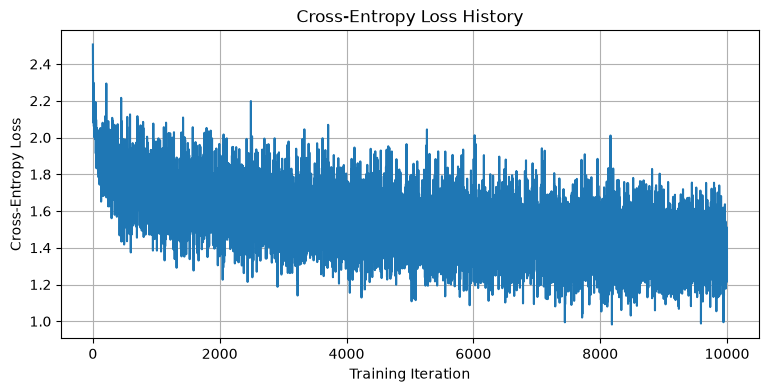

In [11]:
plt.figure(figsize=(9, 4))

plt.plot(loss_history)

plt.title("Cross-Entropy Loss History")
plt.xlabel("Training Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)
plt.show()

In [12]:
def calculate_accuracy(loader, W1, b1, W2, b2):

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            x = inputs.reshape(inputs.shape[0], -1)

            _, _, z2 = forward(x, W1, b1, W2, b2)

            predicted = z2.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


train_acc = calculate_accuracy(
    trainloader, W1, b1, W2, b2
)

test_acc = calculate_accuracy(
    testloader, W1, b1, W2, b2
)

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")

Training Accuracy: 53.04%
Test Accuracy: 48.28%
